# Détection d'anomalies sur C-MAPSS FD001 — MLP sur fenêtres glissantes

**Tâche.** Classification binaire d'une *fenêtre* de L cycles consécutifs : `1 = anomalie`, `0 = normal`.
C-MAPSS ne contient **pas** d'étiquettes d'anomalie (le jeu a été conçu pour prédire le RUL) :
l'étiquette est **notre construction**, `anomalie = (RUL <= K)`.

**Deux seuils à ne jamais confondre.**

| | porte sur | rôle | choisi comment |
|---|---|---|---|
| **K** | le RUL (la réalité) | fabrique l'étiquette **avant** l'entraînement | choix métier (préavis de maintenance), arbitraire ici |
| **τ (tau)** | le score du modèle | transforme un score en décision (alerte si score ≥ τ) | maximise le F-β **sur la validation**, puis **figé** pour le test |

K définit l'épreuve ; τ est notre façon de la passer. Changer K change la tâche, donc deux F1 obtenus
avec des K différents ne sont pas comparables.

**Pourquoi des fenêtres et pas un cycle isolé ?** Le bruit cycle-à-cycle est de l'ordre d'un écart-type :
un seul relevé est peu informatif. Une anomalie est ici **collective** — c'est une *trajectoire* qui dérive,
pas un point aberrant. La fenêtre donne au modèle un bout de trajectoire.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE / "src"))

import data_processing as dp
import evaluate as ev
import models
import visualization as viz

# Paramètres de la tâche. K et beta sont des CHOIX ARBITRAIRES, à justifier par nous,
# et à ne JAMAIS optimiser sur le jeu de test.
L, PAS, K, BETA, SEED = 10, 1, 22, 1.0, 42
DATA = RACINE / "data"
SORTIE = RACINE / "results" / "notebook"
SORTIE.mkdir(parents=True, exist_ok=True)

models.fixer_seed(SEED)
print(f"L={L}  pas={PAS}  K={K}  beta={BETA}  seed={SEED}")

L=10  pas=1  K=22  beta=1.0  seed=42


## 1. Chargement et vérifications

On charge le CSV déjà préparé (Kaggle) et on **vérifie par assertions** les hypothèses dont tout le reste dépend :
100 moteurs, cycles consécutifs sans trou (sinon une fenêtre de 10 lignes ne serait pas 10 vols consécutifs),
et `cycle + RUL` constant par moteur (c'est la définition `RUL = dernier_cycle − cycle`).
Si une assertion casse, le pipeline s'arrête : mieux vaut un arrêt qu'un résultat faux.

In [2]:
prepare = dp.charger_train_prepare(DATA / "train_FD001_prepared.csv")
print(prepare.shape, "lignes x colonnes")
print("moteurs :", prepare["unit_nr"].nunique())
print("durée de vie : min %d, max %d, moyenne %.1f cycles" % (
    prepare.groupby("unit_nr")["cycle"].max().min(),
    prepare.groupby("unit_nr")["cycle"].max().max(),
    prepare.groupby("unit_nr")["cycle"].max().mean()))
prepare.head()

(20631, 13) lignes x colonnes
moteurs : 100
durée de vie : min 128, max 362, moyenne 206.3 cycles


,unit_nr,cycle,sensor2,sensor3,sensor4,sensor7,sensor8,sensor9,sensor15,sensor17,sensor20,sensor21,RUL
0,1,1,-1.721725,-0.134255,-0.925936,1.121141,-0.516338,-0.862813,-0.603816,-0.781710,1.348493,1.194427,191
1,1,2,-1.061780,0.211528,-0.643726,0.431930,-0.798093,-0.958818,-0.275852,-0.781710,1.016528,1.236922,190
2,1,3,-0.661813,-0.413166,-0.525953,1.008155,-0.234584,-0.557139,-0.649144,-2.073094,0.739891,0.503423,189
3,1,4,-0.661813,-1.261314,-0.784831,1.222827,0.188048,-0.713826,-1.971665,-0.781710,0.352598,0.777792,188
4,1,5,-0.621816,-1.251528,-0.301518,0.714393,-0.516338,-0.457059,-0.339845,-0.136018,0.463253,1.059552,187


## 2. Étiquetage et découpage train / validation

`anomalie = (RUL <= K)` dans une **nouvelle colonne** : on ne touche pas à `RUL`, dont on aura besoin
pour les métriques métier (délai d'alerte, erreurs par tranche de RUL).

**Le découpage se fait par MOTEUR, pas par fenêtre.** Avec un pas de 1, deux fenêtres voisines partagent
9 cycles sur 10 : si on mélangeait les fenêtres au hasard, la validation contiendrait des quasi-copies des
fenêtres d'entraînement et donnerait un score artificiellement bon. 80 moteurs / 20 moteurs, seed fixée.

In [3]:
prepare = dp.ajouter_etiquette(prepare, K)
df_train, df_val = dp.decouper_par_moteur(prepare, frac_val=0.2, seed=SEED)

moteurs_tr, moteurs_va = set(df_train["unit_nr"]), set(df_val["unit_nr"])
assert moteurs_tr.isdisjoint(moteurs_va)
print(f"train : {len(moteurs_tr)} moteurs | validation : {len(moteurs_va)} moteurs | aucun moteur en commun")
print("taux de cycles anormaux (train) : %.4f" % df_train["anomalie"].mean())

train : 80 moteurs | validation : 20 moteurs | aucun moteur en commun
taux de cycles anormaux (train) : 0.1097


## 3. Fenêtres glissantes

Pour chaque moteur séparément, la fenêtre qui se termine au cycle *t* contient les cycles *[t−L+1 .. t]*,
avec *t* allant de *L−1* au dernier cycle, par pas de 1.

Trois décisions importantes :

1. **Étiquette = celle du dernier cycle.** C'est la décision réelle : à l'instant *t*, on ne voit que le passé.
   (Alternative écartée : « anormale si elle contient un cycle anormal », qui ferait alerter trop tôt.)
2. **Pas de padding** pour les L−1 premiers cycles : après standardisation, 0 = « moteur moyen »,
   donc remplir de zéros fabriquerait des données. On ne prédit simplement pas sur ces cycles.
   Un moteur de *n* cycles donne donc *n − L + 1* fenêtres. C'est une **limite du MLP** à citer :
   un LSTM n'aurait pas cette contrainte.
3. **Aucune fenêtre n'enjambe deux moteurs** (on travaille dans un `groupby`).

L'aplatissement met bout à bout les 10 capteurs du cycle le plus ancien, puis ceux du suivant, etc.
L'ordre chronologique est conservé, mais **le MLP ne sait pas que ce sont des pas de temps** : il a un poids
distinct pour chaque position, sans partage de poids (contrairement à une convolution). Autre limite à citer.

In [4]:
X_train, y_train, meta_train = dp.creer_fenetres(df_train, L, PAS)
X_val,   y_val,   meta_val   = dp.creer_fenetres(df_val,   L, PAS)
print("X_train", X_train.shape, " (L x 10 capteurs =", L * 10, "entrées)")
print("X_val  ", X_val.shape)

X_train (16059, 100)  (L x 10 capteurs = 100 entrées)
X_val   (3672, 100)


### Test unitaire du fenêtrage

Un moteur fictif de 200 cycles, avec L = 10 et K = 22, doit donner **191 fenêtres dont 23 positives**
(191 = 200 − 10 + 1 ; 23 = les cycles de RUL 0 à 22 inclus). Les tests complets sont dans
`tests/test_fenetres.py` (ordre chronologique, absence de padding, aucune fenêtre à cheval sur deux moteurs).

In [5]:
import subprocess
print(subprocess.run([sys.executable, str(RACINE / "tests" / "test_fenetres.py")],
                     capture_output=True, text=True).stdout)

OK : 191 fenêtres, 23 positives
OK : ordre chronologique, pas de padding
OK : aucune fenêtre à cheval sur deux moteurs
OK : 80 / 20 moteurs disjoints

Tous les tests passent.



## 4. Jeu de test officiel

Le CSV Kaggle est déjà standardisé, mais **le scaler n'a pas été sauvegardé**. Pour traiter le test avec
exactement la même transformation, on le **reproduit** (StandardScaler ajusté sur les 10 capteurs des
100 moteurs de `train_FD001.txt` brut) et on **vérifie par `np.allclose`** qu'il redonne le CSV préparé.
Si la vérification échoue, on s'arrête : appliquer au test un scaler différent de celui du train rendrait
les entrées incohérentes avec ce que le modèle a appris.

> **Limite assumée** : ce scaler a été ajusté sur les 100 moteurs, donc aussi sur nos 20 moteurs de validation.
> C'est une **fuite mineure** (seulement deux statistiques globales, moyenne et écart-type), héritée du dataset Kaggle.
> On la déclare plutôt que de la masquer.

Le test est **tronqué avant la panne** : `RUL_FD001.txt` donne le RUL du dernier cycle observé de chaque moteur,
d'où `RUL(t) = RUL_final + (cycle_max − cycle(t))`.

In [6]:
brut_train = dp.charger_brut(DATA / "train_FD001.txt")
scaler = dp.ajuster_et_verifier_scaler(brut_train, prepare)
print("Scaler reproduit et VÉRIFIÉ (np.allclose) contre train_FD001_prepared.csv.")

import joblib
joblib.dump(scaler, SORTIE / "scaler.joblib")

brut_test = dp.charger_brut(DATA / "test_FD001.txt")
rul_final = np.loadtxt(DATA / "RUL_FD001.txt").astype(int)
df_test = dp.preparer_test(brut_test, rul_final, scaler, K, L)
X_test, y_test, meta_test = dp.creer_fenetres(df_test, L, PAS)

print("moteurs de test :", df_test["unit_nr"].nunique(),
      "| cycles par moteur : min %d, max %d" % (
          df_test.groupby("unit_nr")["cycle"].count().min(),
          df_test.groupby("unit_nr")["cycle"].count().max()))
print("RUL final : min %d, max %d" % (rul_final.min(), rul_final.max()))

Scaler reproduit et VÉRIFIÉ (np.allclose) contre train_FD001_prepared.csv.
moteurs de test : 100 | cycles par moteur : min 31, max 303
RUL final : min 7, max 145


## 5. Tableau de contrôle

À lire **avant** tout résultat de modèle : ces chiffres disent à quel point la tâche est déséquilibrée et
à quoi se comparer. Le taux de positifs du **test** est beaucoup plus faible que celui du train parce que
le test est tronqué : la plupart des moteurs s'arrêtent loin de la panne et n'ont **aucun** cycle anormal.
Conséquence : les métriques du test ne sont pas comparables telles quelles à celles de la validation.

In [7]:
resumes = {"train": dp.resume_jeu(y_train, meta_train),
           "validation": dp.resume_jeu(y_val, meta_val),
           "test": dp.resume_jeu(y_test, meta_test)}
pd.DataFrame(resumes).T

,n_fenetres,n_positifs,taux_positifs,n_moteurs,n_moteurs_avec_positif
train,16059.0,1840.0,0.114577,80.0,80.0
validation,3672.0,460.0,0.125272,20.0,20.0
test,12196.0,161.0,0.013201,100.0,19.0


## 6. Modèle et entraînement

MLP `100 → 64 → 32 → 1`, ReLU, sortie = **logit** (pas de sigmoïde dans le modèle : `BCEWithLogitsLoss`
combine sigmoïde et entropie croisée de façon numériquement plus stable). Optimiseur Adam.
**Early stopping sur la perte de VALIDATION** : on garde les poids de la meilleure époque — jamais le test.

On entraîne **deux variantes** pour comparer :

- **sans `pos_weight`** : chaque fenêtre pèse pareil ;
- **avec `pos_weight` = n_négatifs / n_positifs** : une fenêtre anormale pèse ≈ 8 fois plus, ce qui pousse
  le modèle vers le rappel. Attention : cela change aussi l'échelle des scores, donc τ s'ajustera différemment.

In [8]:
import types

import train as tr   # train.py ne lit les arguments que dans main(), on peut donc importer ses fonctions

def config(pos_weight):
    return types.SimpleNamespace(seed=SEED, pos_weight=pos_weight, max_epochs=200,
                                 patience=10, batch_size=256, lr=1e-3)

resultats = {}
for pw in (False, True):
    print(f"--- pos_weight = {pw}")
    modele, historique = tr.entrainer(X_train, y_train, X_val, y_val, config(pw))
    resultats[pw] = {"modele": modele, "historique": historique,
                     "s_val": tr.scores(modele, X_val), "s_test": tr.scores(modele, X_test)}

--- pos_weight = False
  early stopping à l'époque 23 (meilleure perte val = 0.0753)
--- pos_weight = True
  early stopping à l'époque 15 (meilleure perte val = 0.2175)


pos_weight = False


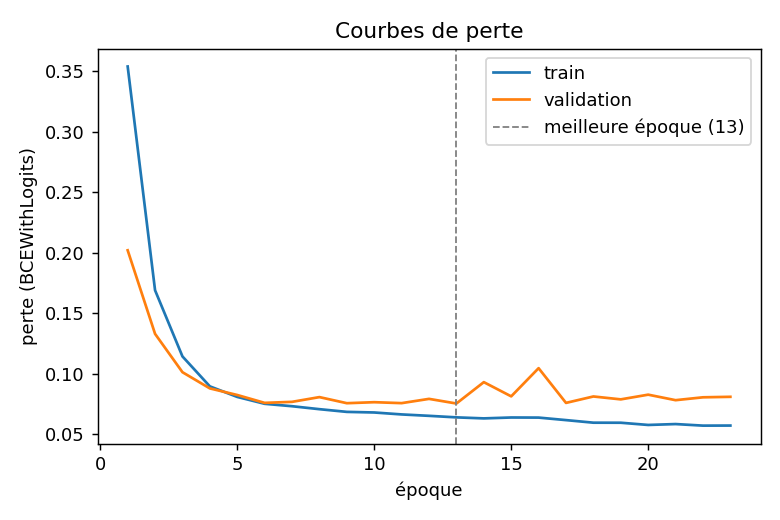

pos_weight = True


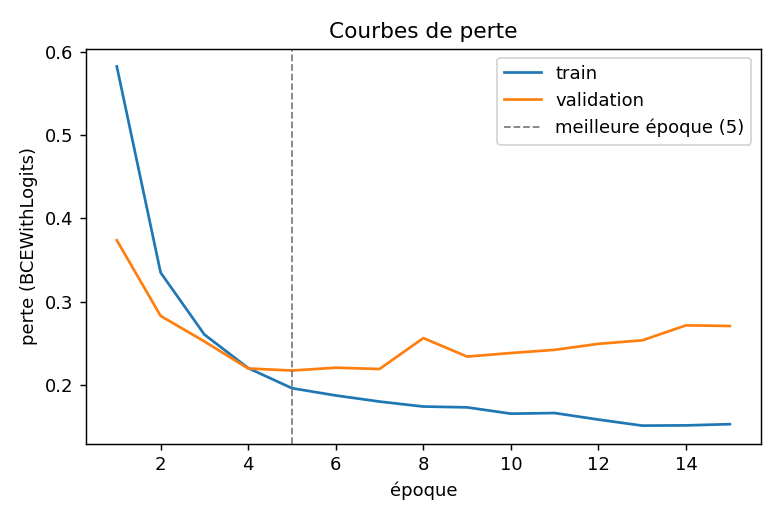

In [9]:
from IPython.display import Image, display
for pw in (False, True):
    chemin = viz.courbes_perte(resultats[pw]["historique"], SORTIE / f"pertes_pw{int(pw)}.png")
    print(f"pos_weight = {pw}")
    display(Image(filename=str(chemin)))

## 7. Choix du seuil τ

τ est choisi **uniquement sur la validation**, comme celui qui maximise le F-β (ici β = 1, donc F1),
via `precision_recall_curve`. Il est ensuite **figé** : on l'applique au test sans le retoucher.
Retoucher τ sur le test reviendrait à regarder la réponse avant de passer l'examen — c'est exactement
la critique faite à certains articles du domaine (seuil optimal choisi sur le test).

On rapporte aussi le **seuil naïf 0,5** pour voir ce que le choix de τ apporte (ou coûte).

In [10]:
for pw in (False, True):
    tau, fbeta = ev.choisir_tau(y_val, resultats[pw]["s_val"], BETA)
    resultats[pw]["tau"] = tau
    print(f"pos_weight = {pw} : tau = {tau:.4f}  (F{BETA:g} validation = {fbeta:.4f})")

pos_weight = False : tau = 0.5314  (F1 validation = 0.8857)
pos_weight = True : tau = 0.8994  (F1 validation = 0.8788)


## 8. Métriques

Trois niveaux, tous calculés par le **même code** (`src/evaluate.py`) sur la validation puis sur le test,
pour qu'un futur modèle (EncDec-AD) soit évalué exactement de la même façon.

- **Niveau 1 — qualité du score, sans seuil** : PR-AUC, à comparer au **taux de positifs** qui est la PR-AUC
  d'un modèle aléatoire. ROC-AUC en secondaire : il paraît très bon quand la classe positive est rare,
  car les vrais négatifs écrasent tout.
- **Niveau 2 — qualité de la décision, à τ figé** : matrice de confusion, précision, rappel, F1 / F-β,
  et l'accuracy comparée à celle du modèle trivial « toujours normal » (= 1 − taux de positifs).
  Sur le test, ce trivial dépasse 98 % : **l'accuracy seule est inacceptable ici**.
- **Niveau 3 — métier** : délai d'alerte, fausses alertes par moteur, moteurs détectés.

In [11]:
lignes = {}
for pw in (False, True):
    tau = resultats[pw]["tau"]
    for jeu, y, s in (("validation", y_val, resultats[pw]["s_val"]),
                      ("test", y_test, resultats[pw]["s_test"])):
        lignes[f"{jeu} | tau (pw={pw})"] = ev.metriques_classification(y, s, tau, BETA)
        lignes[f"{jeu} | 0.5 (pw={pw})"] = ev.metriques_classification(y, s, 0.5, BETA)

tableau = pd.DataFrame(lignes)
tableau.round(4)

,validation | tau (pw=False),validation | 0.5 (pw=False),test | tau (pw=False),test | 0.5 (pw=False),validation | tau (pw=True),validation | 0.5 (pw=True),test | tau (pw=True),test | 0.5 (pw=True)
tau,0.5314,0.5000,0.5314,0.5000,0.8994,0.5000,0.8994,0.5000
taux_positifs,0.1253,0.1253,0.0132,0.0132,0.1253,0.1253,0.0132,0.0132
accuracy_toujours_normal,0.8747,0.8747,0.9868,0.9868,0.8747,0.8747,0.9868,0.9868
VP,399.0000,400.0000,112.0000,114.0000,388.0000,440.0000,101.0000,145.0000
FP,42.0000,46.0000,37.0000,41.0000,35.0000,201.0000,29.0000,217.0000
FN,61.0000,60.0000,49.0000,47.0000,72.0000,20.0000,60.0000,16.0000
VN,3170.0000,3166.0000,11998.0000,11994.0000,3177.0000,3011.0000,12006.0000,11818.0000
accuracy,0.9719,0.9711,0.9929,0.9928,0.9709,0.9398,0.9927,0.9809
precision,0.9048,0.8969,0.7517,0.7355,0.9173,0.6864,0.7769,0.4006
rappel,0.8674,0.8696,0.6957,0.7081,0.8435,0.9565,0.6273,0.9006


### Comparaison des deux variantes et des deux seuils

Points à regarder : le **gain de PR-AUC** par rapport au hasard (ligne `PR_AUC` contre `PR_AUC_hasard`),
l'écart entre l'accuracy du modèle et celle du trivial « toujours normal », et l'effet du seuil naïf 0,5.

In [12]:
tableau.loc[["taux_positifs", "accuracy_toujours_normal", "accuracy",
             "precision", "rappel", "F1", "PR_AUC", "PR_AUC_hasard", "ROC_AUC"]].round(4).T

,taux_positifs,accuracy_toujours_normal,accuracy,precision,rappel,F1,PR_AUC,PR_AUC_hasard,ROC_AUC
validation | tau (pw=False),0.1253,0.8747,0.9719,0.9048,0.8674,0.8857,0.9559,0.1253,0.9917
validation | 0.5 (pw=False),0.1253,0.8747,0.9711,0.8969,0.8696,0.8830,0.9559,0.1253,0.9917
test | tau (pw=False),0.0132,0.9868,0.9929,0.7517,0.6957,0.7226,0.7976,0.0132,0.9914
test | 0.5 (pw=False),0.0132,0.9868,0.9928,0.7355,0.7081,0.7215,0.7976,0.0132,0.9914
validation | tau (pw=True),0.1253,0.8747,0.9709,0.9173,0.8435,0.8788,0.9555,0.1253,0.9915
validation | 0.5 (pw=True),0.1253,0.8747,0.9398,0.6864,0.9565,0.7993,0.9555,0.1253,0.9915
test | tau (pw=True),0.0132,0.9868,0.9927,0.7769,0.6273,0.6942,0.7673,0.0132,0.9892
test | 0.5 (pw=True),0.0132,0.9868,0.9809,0.4006,0.9006,0.5545,0.7673,0.0132,0.9892


In [13]:
metier = {}
for pw in (False, True):
    par_moteur, resume = ev.metriques_metier(meta_test, y_test, resultats[pw]["s_test"],
                                             resultats[pw]["tau"], K)
    resultats[pw]["par_moteur"] = par_moteur
    metier[f"pos_weight={pw}"] = resume
pd.DataFrame(metier)

,pos_weight=False,pos_weight=True
n_moteurs,100.0,100.0
n_moteurs_avec_anomalie,19.0,19.0
n_moteurs_anomalie_detectes,15.0,14.0
n_moteurs_anomalie_ayant_alerte,15.0,14.0
delai_alerte_median_si_alerte,23.0,21.5
total_fausses_alertes,37.0,29.0
n_moteurs_avec_fausse_alerte,10.0,7.0


**Lecture des métriques métier.** `delai_alerte_median` est le RUL au moment de la première alerte :
c'est le préavis réellement offert à la maintenance, en nombre de vols. `n_moteurs_anomalie_detectes`
compte les moteurs réellement en zone d'anomalie pour lesquels on a alerté dans cette zone — c'est la
question qui compte vraiment, bien plus que le nombre de fenêtres bien classées.

In [14]:
for pw in (False, True):
    print(f"--- erreurs par tranche de RUL, pos_weight = {pw} (tau = {resultats[pw]['tau']:.3f})")
    print(ev.erreurs_par_tranche(meta_test, y_test, resultats[pw]["s_test"],
                                 resultats[pw]["tau"], K).to_string(index=False))
    print()

--- erreurs par tranche de RUL, pos_weight = False (tau = 0.531)
  tranche  n_fenetres  n_positifs  FP  FN
   (2, 7]           1           1   0   0
  (7, 12]          32          32   0   0
 (12, 17]          49          49   0   9
 (17, 22]          79          79   0  40
 (22, 27]          97           0  17   0
 (27, 32]         124           0  11   0
 (32, 37]         130           0   2   0
 (37, 42]         140           0   1   0
 (42, 47]         141           0   2   0
 (47, 52]         159           0   4   0
(52, 332]       11244           0   0   0

--- erreurs par tranche de RUL, pos_weight = True (tau = 0.899)
  tranche  n_fenetres  n_positifs  FP  FN
   (2, 7]           1           1   0   0
  (7, 12]          32          32   0   1
 (12, 17]          49          49   0  11
 (17, 22]          79          79   0  48
 (22, 27]          97           0  12   0
 (27, 32]         124           0   9   0
 (32, 37]         130           0   2   0
 (37, 42]         140         

Les tranches sont alignées sur K. On s'attend à ce que les erreurs se concentrent **juste autour de RUL ≈ K** :
une fenêtre à RUL = 23 et une à RUL = 21 sont physiquement presque identiques mais portent des étiquettes
opposées. Ces erreurs-là sont **inévitables** et ne traduisent pas une faiblesse du modèle, mais le caractère
arbitraire de la frontière K.

## 9. Graphiques

On garde la variante **sans `pos_weight`** pour les figures (voir le tableau ci-dessus pour la comparaison).

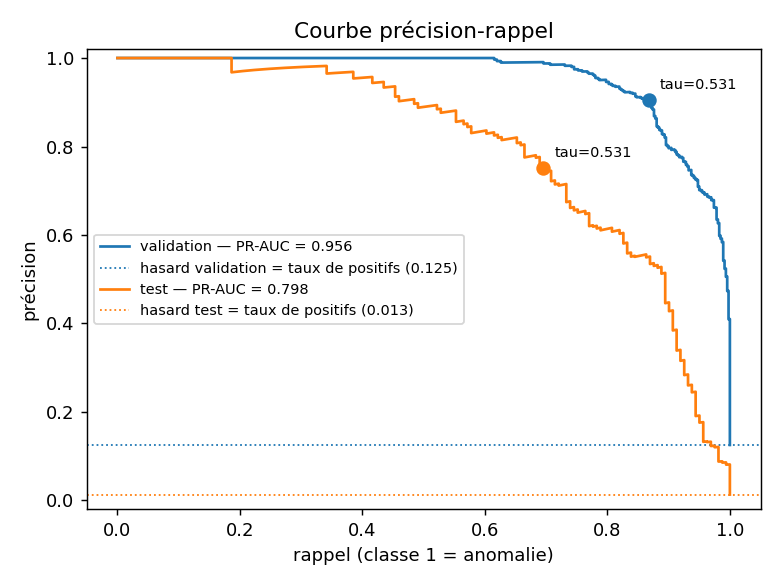

In [15]:
MEILLEUR = False     # variante illustrée ; la comparaison chiffrée reste dans les tableaux ci-dessus
tau = resultats[MEILLEUR]["tau"]
s_val, s_test = resultats[MEILLEUR]["s_val"], resultats[MEILLEUR]["s_test"]

display(Image(filename=str(viz.courbe_pr(
    {"validation": (y_val, s_val, tau), "test": (y_test, s_test, tau)}, SORTIE / "courbe_pr.png"))))

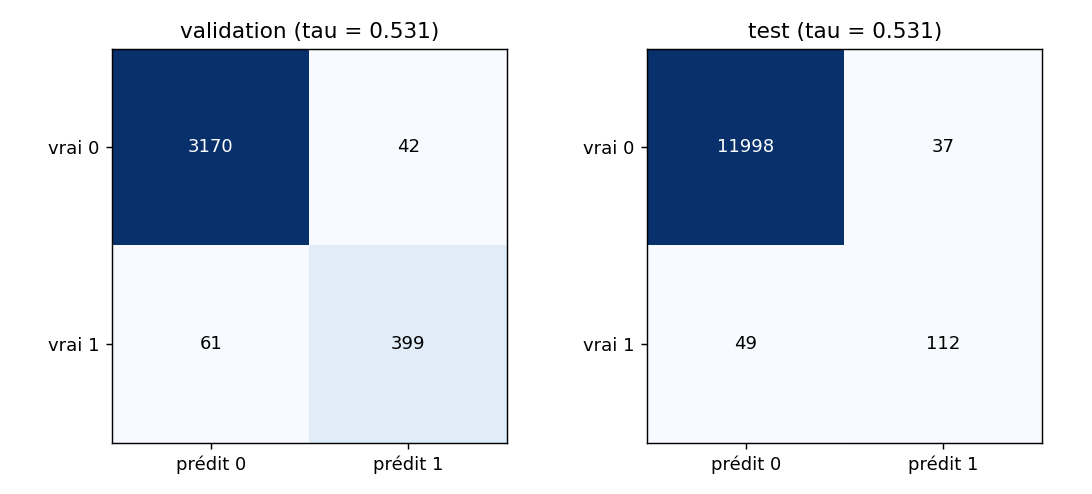

In [16]:
m = {"validation": ev.metriques_classification(y_val, s_val, tau, BETA),
     "test": ev.metriques_classification(y_test, s_test, tau, BETA)}
display(Image(filename=str(viz.matrice_confusion(m, SORTIE / "matrices_confusion.png"))))

### Score en fonction du RUL

Les 4 moteurs sont choisis **sans regarder les scores** : les 3 au RUL final le plus faible (ils ont le plus
de cycles en zone d'anomalie) et celui au RUL final le plus élevé (il est loin de la panne, son score doit
rester bas). C'est la figure la plus parlante à l'oral : on doit voir le score **monter** à l'approche de la panne.

moteurs tracés : [34, 31, 68, 25]


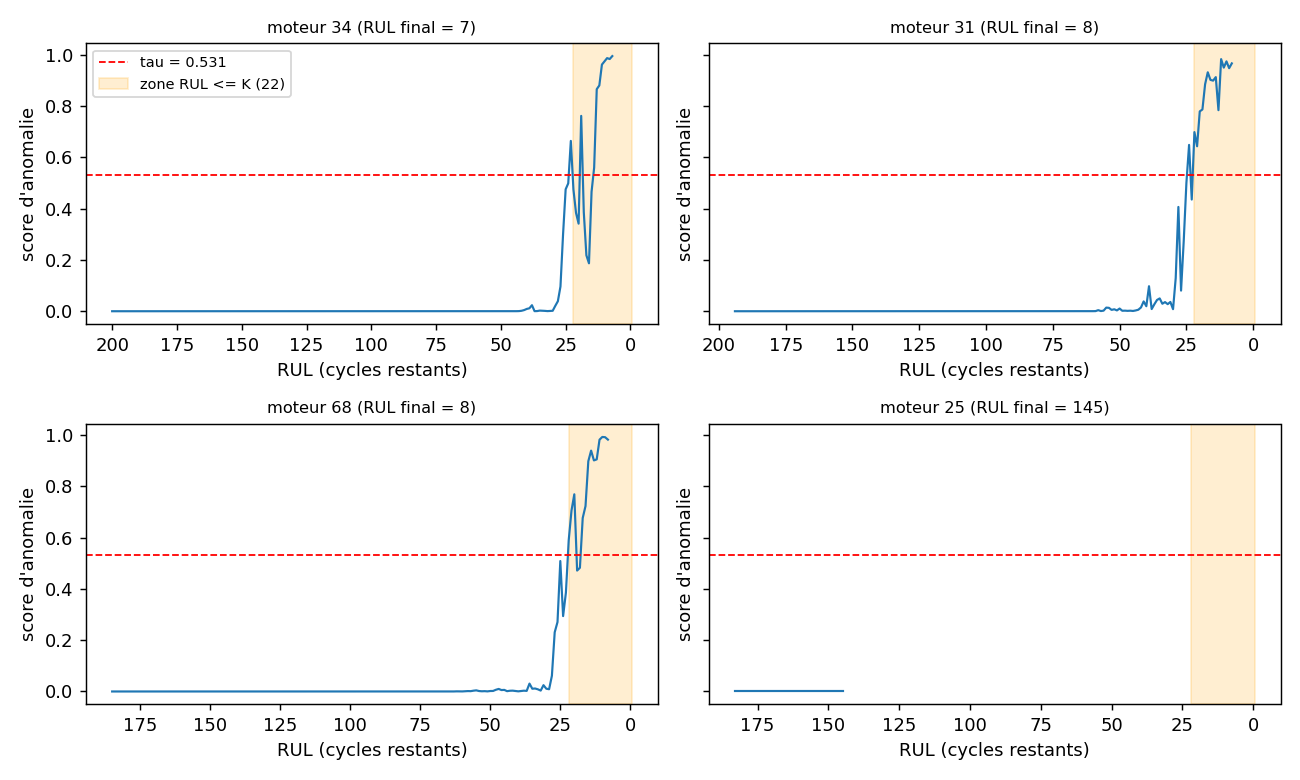

In [17]:
moteurs = viz.choisir_4_moteurs(resultats[MEILLEUR]["par_moteur"], rul_final)
print("moteurs tracés :", moteurs)
display(Image(filename=str(viz.score_vs_rul(meta_test, s_test, tau, K, moteurs,
                                            SORTIE / "score_vs_rul.png"))))

In [18]:
(SORTIE / "metriques_notebook.json").write_text(json.dumps({
    "parametres": {"L": L, "pas": PAS, "K": K, "beta": BETA, "seed": SEED},
    "resumes_jeux": resumes,
    "tau": {str(pw): resultats[pw]["tau"] for pw in (False, True)},
    "metriques": {k: v for k, v in lignes.items()},
    "metier_test": metier,
}, indent=2))
print("métriques écrites dans", SORTIE / "metriques_notebook.json")

métriques écrites dans /home/elhiann/Documents/cours/idu-5/data/proj2/projet/results/notebook/metriques_notebook.json


## 10. Limites

**Sur les données**
- **Fuite mineure déclarée** : la standardisation et la sélection des 10 capteurs ont été calculées sur les
  100 moteurs de train, donc aussi sur nos 20 moteurs de validation. Faible (deux statistiques globales),
  mais réelle — nous l'héritons du dataset Kaggle et nous le disons plutôt que de le cacher.
- **K est arbitraire.** Il définit la tâche. Il devrait venir d'un besoin métier (préavis de maintenance en
  nombre de vols), pas d'une optimisation. Une analyse de sensibilité (K = 15, 22, 30, 50) doit se comparer
  sur le **gain de PR-AUC par rapport au taux de positifs**, jamais sur des F1 bruts : changer K change l'épreuve.
- **Le test est tronqué** : peu de fenêtres positives et une large majorité de moteurs sans aucun positif.
  Les chiffres du test portent donc sur peu d'exemples positifs et sont fragiles (un bootstrap par moteur
  donnerait un intervalle de confiance — non fait ici).
- **Retirer les capteurs corrélés** (choix du notebook Kaggle) peut jeter du signal et supprime la structure
  inter-capteurs qu'un autoencodeur exploiterait. Le seuil d'écart-type 0,01 portait sur des valeurs **brutes**,
  donc dépendantes des unités.
- Pipeline **FD001 seulement** : une seule condition opératoire, un seul mode de panne. Sur FD002
  (6 conditions), il faudrait normaliser par condition, sinon un régime sain jamais vu serait signalé à tort
  (« nouveau ≠ anormal »).

**Sur la méthode**
- **Chevauchement des fenêtres** : 90 % entre voisines. D'où le découpage par moteur ; mais les fenêtres d'un
  même jeu restent fortement corrélées, donc le nombre de fenêtres surestime la quantité d'information réelle.
- **Limites du MLP à fenêtre aplatie** : entrée de taille fixe, aucune notion d'ordre (un poids par position,
  pas de poids partagés comme une convolution), pas de mémoire au-delà de L cycles, et surtout **besoin
  d'étiquettes**. Or en usine on n'a pas de RUL : c'est tout l'intérêt d'apprendre le « normal » sans
  étiquettes (EncDec-AD, prochaine étape).
- **L = 10 n'est pas justifié** expérimentalement à ce stade (une variation de L reste à faire).
- L'hypothèse « le début de vie est normal » est une **hypothèse**, pas un fait vérifié.